# SUPPORT VECTOR REGRESSION (SVR) – Dự đoán giá RAM

Notebook được chuyển từ file Python gốc. Đặt `ram_pricing_intelligence_2026.csv` cùng thư mục với notebook, sau đó chạy lần lượt các cell từ trên xuống.

Nếu thiếu thư viện, chạy trong một cell: `%pip install numpy pandas matplotlib joblib scikit-learn`.

In [1]:
# ============================================================
# DUONG - SUPPORT VECTOR REGRESSION (SVR)
# Du doan gia RAM tu bo du lieu ram_pricing_intelligence_2026.csv
# Chay: py svr_ram_duong.py
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVR
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [3]:
# 1. DOC DU LIEU
DATA_FILE = "ram_pricing_intelligence_2026.csv"

if not os.path.exists(DATA_FILE):
    raise FileNotFoundError(
        f"Khong tim thay {DATA_FILE}. Hay dat file CSV cung thu muc voi file Python."
    )

df = pd.read_csv(DATA_FILE)
print("Kich thuoc du lieu ban dau:", df.shape)
print("\n5 dong dau tien:")
print(df.head())
print("\nThong tin du lieu:")
print(df.info())

Kich thuoc du lieu ban dau: (2899, 17)

5 dong dau tien:
  ram_generation     brand    seller_id condition  \
0           DDR4  SK hynix  Seller_0001      Used   
1           DDR4    A-Tech  Seller_0002       New   
2           DDR4   Crucial  Seller_0003      Used   
3           DDR4  SK hynix  Seller_0004      Used   
4           DDR4       RAM  Seller_0005      Used   

                                               title  capacity_gb  \
0  SK Hynix 64GB 4DRx4 PC4-2400T DDR4 ECC Server ...         64.0   
1  A-Tech 32GB 2x 16GB PC4-21300 Laptop SODIMM 26...         32.0   
2  16GB Crucial Micron DDR4-2133 PC4-17000 RDIMM ...         16.0   
3  SK HYNIX 32GB HMA84GR7MFR4N-UH DDR4-2400 2Rx4 ...         32.0   
4  Mixed Brand 8GB DDR4 Desktop RAM PC4 UDIMM - C...          8.0   

   bus_speed_mhz unit_type   price  wasPrice  available    sold  \
0         2400.0    Single  229.00       NaN        6.0     2.0   
1         2666.0  Dual Kit  231.98       NaN       10.0  1728.0   
2       

In [4]:
# 2. CHON CAC THUOC TINH
# X: thong tin cau hinh RAM
# y: gia RAM (price)
categorical_features = [
    "ram_generation",
    "brand",
    "condition",
    "unit_type",
    "type"
]
numeric_features = [
    "capacity_gb",
    "bus_speed_mhz",
    "is_bulk_server"
]
features = categorical_features + numeric_features
target = "price"

missing_columns = [c for c in features + [target] if c not in df.columns]
if missing_columns:
    raise ValueError(f"CSV thieu cac cot: {missing_columns}")

data = df[features + [target]].copy()
data[target] = pd.to_numeric(data[target], errors="coerce")
data = data.dropna(subset=[target])
data = data[data[target] > 0]

# Loai bo cac gia tri gia qua bat thuong (tren phan vi 99%)
# de giam anh huong cua cac listing gia cuc cao/khac biet.
price_limit = data[target].quantile(0.99)
data = data[data[target] <= price_limit]

X = data[features]
y = data[target]

print("\nSo dong sau khi lam sach:", len(data))
print(f"Nguong gia toi da giu lai (phan vi 99%): {price_limit:.2f} USD")


So dong sau khi lam sach: 2870
Nguong gia toi da giu lai (phan vi 99%): 1271.12 USD


In [5]:
# 3. CHIA DU LIEU TRAIN/TEST
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print("\nSo mau train:", len(X_train))
print("So mau test:", len(X_test))


So mau train: 2296
So mau test: 574


In [6]:
# 4. TIEN XU LY
# Bien so: dien gia tri thieu bang trung vi va chuan hoa.
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Bien chu: dien gia tri thieu bang gia tri pho bien nhat,
# sau do ma hoa One-Hot.
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

In [7]:
# 5. XAY DUNG MO HINH SVR
svr_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("svr", SVR(kernel="rbf", C=100, epsilon=0.1, gamma="scale"))
])

# Chuyen y sang log(1+y) de giam do lech cua phan bo gia.
# Khi du doan, mo hinh tu chuyen nguoc ve USD.
model = TransformedTargetRegressor(
    regressor=svr_pipeline,
    func=np.log1p,
    inverse_func=np.expm1
)

In [8]:
# 6. HUAN LUYEN
print("\nDang huan luyen mo hinh SVR...")
model.fit(X_train, y_train)


Dang huan luyen mo hinh SVR...


,"regressor regressor: object, default=NoneRegressor object such as derived from:class:`~sklearn.base.RegressorMixin`. This regressor willautomatically be cloned each time prior to fitting. If `regressor isNone`, :class:`~sklearn.linear_model.LinearRegression` is created and used.",Pipeline(step... SVR(C=100))])
,"func func: function, default=NoneFunction to apply to `y` before passing to :meth:`fit`. Cannot be setat the same time as `transformer`. If `func is None`, the function used will bethe identity function. If `func` is set, `inverse_func` also needs to beprovided. The function needs to return a 2-dimensional array.",<ufunc 'log1p'>
,"inverse_func inverse_func: function, default=NoneFunction to apply to the prediction of the regressor. Cannot be set atthe same time as `transformer`. The inverse function is used to returnpredictions to the same space of the original training labels. If`inverse_func` is set, `func` also needs to be provided. The inversefunction needs to return a 2-dimensional array.",<ufunc 'expm1'>
,"transformer transformer: object, default=NoneEstimator object such as derived from:class:`~sklearn.base.TransformerMixin`. Cannot be set at the same timeas `func` and `inverse_func`. If `transformer is None` as well as`func` and `inverse_func`, the transformer will be an identitytransformer. Note that the transformer will be cloned during fitting.Also, the transformer is restricting `y` to be a numpy array.",None
,"check_inverse check_inverse: bool, default=TrueWhether to check that `transform` followed by `inverse_transform`or `func` followed by `inverse_func` leads to the original targets.",True
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](8,)","['ram_generation','brand','condition',...,'capacity_gb','bus_speed_mhz', 'is_bulk_server']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying regressor exposes such an attribute when fit... versionadded:: 0.24,int,8
regressor_ regressor_: objectFitted regressor.,Pipeline,Pipeline(step... SVR(C=100))])
transformer_ transformer_: objectTransformer used in :meth:`fit` and :meth:`predict`.,FunctionTransformer,FunctionTrans...validate=True)
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('svr', ...)]"


In [9]:
# 7. DU DOAN
y_pred = model.predict(X_test)
y_pred = np.maximum(y_pred, 0)

In [10]:
# 8. DANH GIA
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\n========== KET QUA MO HINH SVR ==========")
print(f"MAE  : {mae:.2f} USD")
print(f"MSE  : {mse:.2f}")
print(f"RMSE : {rmse:.2f} USD")
print(f"R2   : {r2:.4f}")


========== KET QUA MO HINH SVR ==========
MAE  : 56.61 USD
MSE  : 14014.57
RMSE : 118.38 USD
R2   : 0.6600


In [11]:
# 9. BANG SO SANH GIA THUC TE VA DU DOAN
comparison = pd.DataFrame({
    "Gia thuc te (USD)": y_test.values,
    "Gia du doan (USD)": y_pred
})
comparison["Sai so (USD)"] = (
    comparison["Gia thuc te (USD)"] - comparison["Gia du doan (USD)"]
)
print("\n10 ket qua du doan dau tien:")
print(comparison.head(10).round(2).to_string(index=False))
comparison.to_csv("svr_ram_predictions.csv", index=False, encoding="utf-8-sig")


10 ket qua du doan dau tien:
 Gia thuc te (USD)  Gia du doan (USD)  Sai so (USD)
             54.99             100.26        -45.27
             75.00              60.89         14.11
             44.95              49.78         -4.83
            429.99             364.29         65.70
            325.00             281.31         43.69
            152.95             169.18        -16.23
            224.93             152.25         72.68
            269.99             404.95       -134.96
             96.95              85.57         11.38
             75.00              96.18        -21.18


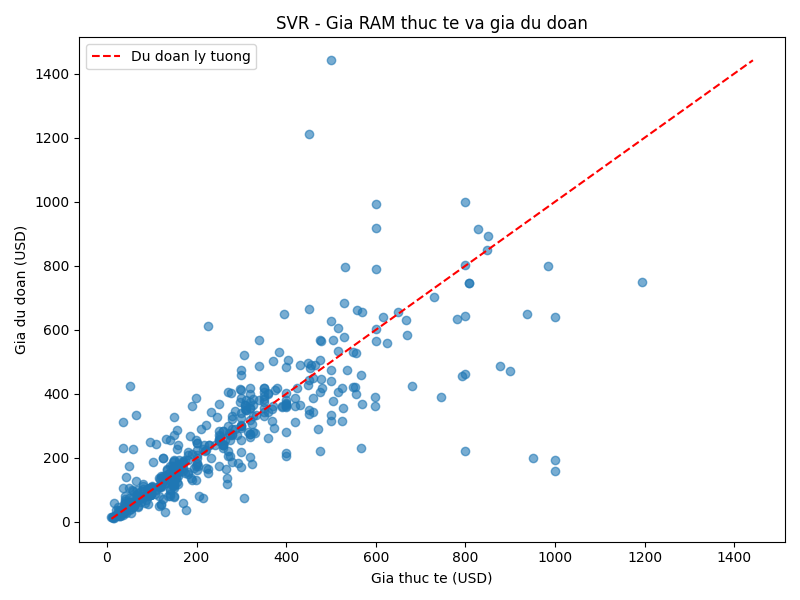

In [ ]:
# 10. VE BIEU DO
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.6)
low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())
plt.plot([low, high], [low, high], "r--", label="Du doan ly tuong")
plt.xlabel("Gia thuc te (USD)")
plt.ylabel("Gia du doan (USD)")
plt.title("SVR - Gia RAM thuc te va gia du doan")
plt.legend()
plt.tight_layout()
plt.savefig("svr_ram_actual_vs_predicted.png", dpi=150)
plt.show()

In [12]:
# 11. LUU MO HINH
joblib.dump(model, "svr_ram_model.pkl")
print("\nDa luu:")
print("- svr_ram_model.pkl")
print("- svr_ram_predictions.csv")
print("- svr_ram_actual_vs_predicted.png")
print("\nHOAN THANH BAI TOAN SVR!")


Da luu:
- svr_ram_model.pkl
- svr_ram_predictions.csv
- svr_ram_actual_vs_predicted.png

HOAN THANH BAI TOAN SVR!
